In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parents[1]))
from split_data.lib import check_folds, plot_split_overview, plot_fold_overview

from extract_features.lib import *
import extract_features.config as c

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

In [4]:
_, S00_exams_indices, N_S00_exams  = load_s00_conn_memmap()

In [5]:
meta = read_metadata()
labels = np.asarray(meta['pathology']).astype(int)[:N_S00_exams]
patients = np.asarray(meta['patient_id'])[:N_S00_exams]
sex = np.asarray(meta['female']).astype(int)[:N_S00_exams]
age = np.asarray(meta['age_group'])[:N_S00_exams]

Initiate the splitter and create main developmental (train & cv approach) & test (hold out) split with group criterion on sites. Test comprises ~ 20 % of data.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
developmental_set, test_hold_out_set = next(sgkf.split(S00_exams_indices, labels, groups=patients))

Assure no longitudinal patient leakage

In [7]:
assert set(patients[developmental_set]).isdisjoint(patients[test_hold_out_set])

In [8]:
len(test_hold_out_set)/ 1697

0.20271066588096642

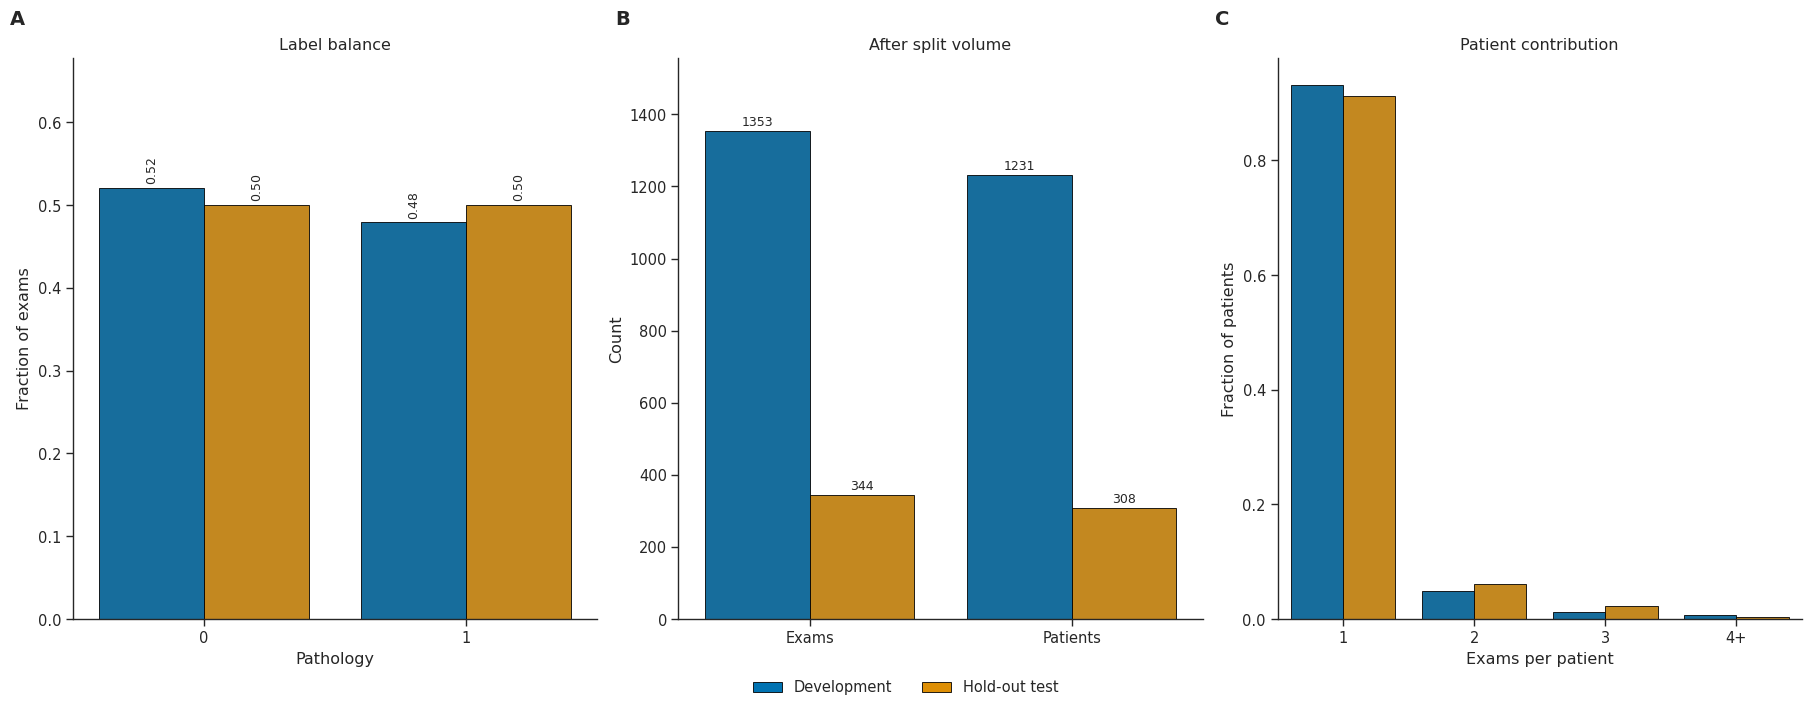

partition  Development  Hold-out test   All
label                                      
0                  705            172   877
1                  648            172   820
All               1353            344  1697


In [9]:
fig, df = plot_split_overview(labels, patients,
                              partitions={"Development": developmental_set, 
                                          "Hold-out test": test_hold_out_set})
plt.show()
print(pd.crosstab(df["label"], df["partition"], margins=True))

Now the test set is left aside for later. The developmental set is divided into new 10 StratifiedGroupFolds and the folds are saved for comparison possibility across models' hyperparameters.

In [10]:
developmental_sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)


In [11]:
developmental_folds = [fold_idx for _, fold_idx in developmental_sgkf.split(developmental_set, labels[developmental_set], groups=patients[developmental_set])]
developmental_folds = [developmental_set[pos] for pos in developmental_folds]


OK: 10 folds, 1353 samples, patient-disjoint, test set untouched


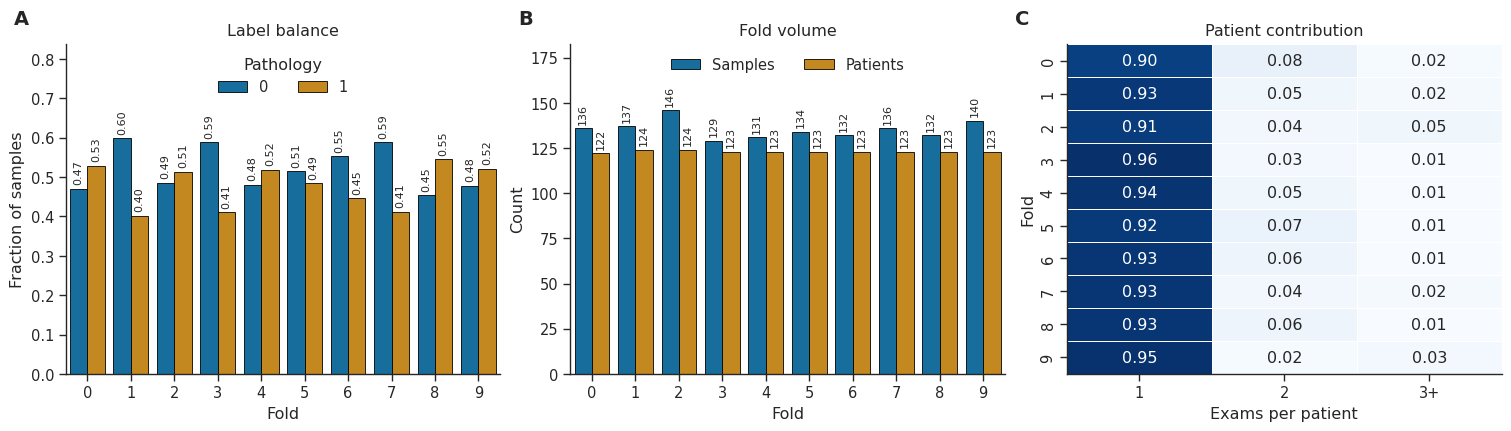

      samples  patients  pathology
fold                              
0         136       122      0.529
1         137       124      0.401
2         146       124      0.514
3         129       123      0.411
4         131       123      0.519
5         134       123      0.485
6         132       123      0.447
7         136       123      0.412
8         132       123      0.545
9         140       123      0.521


In [12]:
check_folds(developmental_folds, developmental_set, test_hold_out_set, patients)
fig, fold_df = plot_fold_overview(developmental_folds, labels, patients)
plt.show()

print(fold_df.groupby("fold").agg(samples=("label", "size"),
                                  patients=("patient", "nunique"),
                                  pathology=("label", "mean")).round(3))

Save to file

In [13]:
np.savez("splits/s00_test.npz", np.asarray(test_hold_out_set))
np.savez("splits/s00_developmental.npz", 
         **{f"fold_{k}": f for k, f in enumerate(developmental_folds)}) # type: ignore[arg-type]

Read from file per fold

In [14]:
s = np.load("splits/s00_developmental.npz")
developmental_folds_read_out = [s[f"fold_{k}"] for k in range(len(s.files))]